### 1. Imports and Data Loading

In [3]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

housing = pd.read_csv("/content/drive/MyDrive/Python Programs/kc_house_data.csv")
housing.columns = housing.columns.str.strip()

print("Missing values before cleaning:")
print(housing.isnull().sum())

Missing values before cleaning:
id               0
date             0
price            0
bedrooms         0
bathrooms        0
sqft_living      0
sqft_lot         0
floors           0
waterfront       0
view             0
condition        0
grade            0
sqft_above       0
sqft_basement    0
yr_built         0
yr_renovated     0
zipcode          0
lat              0
long             0
sqft_living15    0
sqft_lot15       0
dtype: int64


### 2. Data Cleaning
- Removing duplicates
- Fixing missing/invalid bedroom and bathroom counts
- Standardizing datetime and numeric features

In [5]:
housing = housing.drop_duplicates()

# Fix missing and invalid bedroom/bathroom counts
rooms = ["bedrooms", "bathrooms"]
for column in rooms:
    housing[column] = pd.to_numeric(housing[column], errors="coerce")
    housing.loc[housing[column] <= 0, column] = np.nan
    housing[column] = housing[column].fillna(housing[column].median())

# Convert sale date to datetime
housing["date"] = pd.to_datetime(housing["date"], errors="coerce")

# Make year columns numeric
for column in ["yr_built", "yr_renovated"]:
    housing[column] = pd.to_numeric(housing[column], errors="coerce")

### 3. Feature Engineering
- House age at sale
- Years since renovation
- Price per square foot (living & lot area)

In [6]:
# Compute age of the house when sold
housing["year_sold"] = housing["date"].dt.year
housing["age_at_sale"] = housing["year_sold"] - housing["yr_built"]

# Compute years elapsed since renovation
housing["years_since_reno"] = np.where(
    housing["yr_renovated"].notna() & (housing["yr_renovated" ] > 0),
    housing["year_sold"] - housing["yr_renovated"],
    np.nan
)

# Mark negative ages / invalid dates as missing
housing.loc[housing["age_at_sale"] < 0, "age_at_sale"] = np.nan
housing.loc[housing["years_since_reno"] < 0, "years_since_reno"] = np.nan

# Price per square foot (living area and lot)
housing["price_per_living_sqft"] = np.where(
    housing["sqft_living"] > 0,
    housing["price"] / housing["sqft_living"],
    np.nan
)

housing["price_per_lot_sqft"] = np.where(
    housing["sqft_lot"] > 0,
    housing["price"] / housing["sqft_lot"],
    np.nan
)

### 4. Outlier Detection and Visualization

Price statistical limits:
Lower limit: -162625.0
Upper limit: 1129575.0
Total outliers: 1146


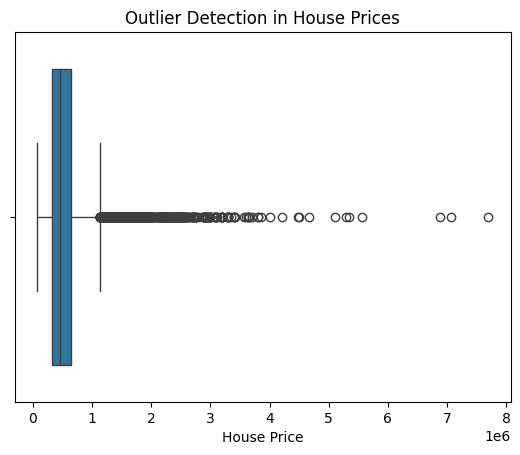

,price,sqft_living,sqft_lot,price_per_living_sqft,price_per_lot_sqft
5,1225000.0,5420,101930,226.014760,12.018052
21,2000000.0,3050,44867,655.737705,44.576192
49,1350000.0,2753,65005,490.374137,20.767633
69,1325000.0,3200,20158,414.062500,65.730727
125,1450000.0,2750,17789,527.272727,81.511046
...,...,...,...,...,...
21568,1700000.0,3830,8963,443.864230,189.668638
21576,3567000.0,4850,10584,735.463918,337.018141
21590,1222500.0,4910,9444,248.981670,129.447268
21597,1575000.0,3410,10125,461.876833,155.555556


In [7]:
# Find price outliers using the IQR method
q1_price = housing["price"].quantile(0.25)
q3_price = housing["price"].quantile(0.75)
iqr_price = q3_price - q1_price

low_limit = q1_price - 1.5 * iqr_price
high_limit = q3_price + 1.5 * iqr_price

housing["price_outlier"] = (
    (housing["price"] < low_limit) |
    (housing["price"] > high_limit)
)

print("Price statistical limits:")
print("Lower limit:", low_limit)
print("Upper limit:", high_limit)
print("Total outliers:", housing["price_outlier"].sum())

# Box plot of prices
sns.boxplot(x=housing["price"])
plt.title("Outlier Detection in House Prices")
plt.xlabel("House Price")
plt.show()

# Show the outlier rows
display(housing[housing["price_outlier"]][
    ["price", "sqft_living", "sqft_lot",
     "price_per_living_sqft", "price_per_lot_sqft"]
])

### 5. Exporting Cleaned Data

In [8]:
# Export the cleaned data
housing.to_csv("house_sales_cleaned.csv", index=False)

print("Cleaned data exported successfully.")
display(housing.head())

Cleaned data exported successfully.


,id,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,...,lat,long,sqft_living15,sqft_lot15,year_sold,age_at_sale,years_since_reno,price_per_living_sqft,price_per_lot_sqft,price_outlier
0,7129300520,2014-10-13,221900.0,3.0,1.00,1180,5650,1.0,0,0,...,47.5112,-122.257,1340,5650,2014,59.0,NaN,188.050847,39.274336,False
1,6414100192,2014-12-09,538000.0,3.0,2.25,2570,7242,2.0,0,0,...,47.7210,-122.319,1690,7639,2014,63.0,23.0,209.338521,74.288870,False
2,5631500400,2015-02-25,180000.0,2.0,1.00,770,10000,1.0,0,0,...,47.7379,-122.233,2720,8062,2015,82.0,NaN,233.766234,18.000000,False
3,2487200875,2014-12-09,604000.0,4.0,3.00,1960,5000,1.0,0,0,...,47.5208,-122.393,1360,5000,2014,49.0,NaN,308.163265,120.800000,False
4,1954400510,2015-02-18,510000.0,3.0,2.00,1680,8080,1.0,0,0,...,47.6168,-122.045,1800,7503,2015,28.0,NaN,303.571429,63.118812,False
